In [1]:

# Imports and Project Configuration

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV,
    GridSearchCV,
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

# Project Paths

PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

# add original folder into PYTHONPATH
project_root = Path().resolve().parent   
sys.path.append(str(project_root))

from ml.churn_model.models.evaluate import (
    evaluate_classifier,
)


PROCESSED_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
)

# Load Processed Data


X_train = pd.read_csv(
    PROCESSED_DATA_DIR
    / "X_train.csv"
)

X_test = pd.read_csv(
    PROCESSED_DATA_DIR
    / "X_test.csv"
)

y_train = pd.read_csv(
    PROCESSED_DATA_DIR
    / "y_train.csv"
).squeeze("columns")

y_test = pd.read_csv(
    PROCESSED_DATA_DIR
    / "y_test.csv"
).squeeze("columns")


print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)



X_train: (5634, 64)
X_test : (1409, 64)
y_train: (5634,)
y_test : (1409,)


In [2]:
# Load Baseline Model Metrics
BASELINE_METRICS_PATH = (
    PROJECT_ROOT
    / "artifacts"
    / "metrics"
    / "baseline_metrics.csv"
)


if not BASELINE_METRICS_PATH.exists():
    raise FileNotFoundError(
        f"Baseline metrics not found: "
        f"{BASELINE_METRICS_PATH}"
    )


baseline_results = pd.read_csv(
    BASELINE_METRICS_PATH
)


baseline_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.797019,0.646667,0.518717,0.575668,0.841975,0.635763
1,Decision Tree,0.791341,0.609290,0.596257,0.602703,0.825904,0.616716
2,Random Forest,0.780696,0.607261,0.491979,0.543575,0.823377,0.611810
3,Gradient Boosting,0.807665,0.687273,0.505348,0.582435,0.847193,0.661443


In [3]:
# Verify Engineered Features
engineered_feature_keywords = [
    "tenure_group",
    "is_new_customer",
    "is_loyal_customer",
    "avg_monthly_spend",
    "customer_value",
    "is_long_term_contract",
    "automatic_payment",
    "is_electronic_check",
    "has_tech_support",
    "has_online_security",
    "num_support_services",
    "has_support_service",
    "num_services",
    "uses_streaming",
    "has_family",
]


engineered_columns = [
    column
    for column in X_train.columns
    if any(
        keyword in column
        for keyword
        in engineered_feature_keywords
    )
]


print(
    "Engineered features found:",
    len(engineered_columns)
)


display(
    pd.DataFrame(
        {
            "Engineered Feature":
                engineered_columns
        }
    )
)

Engineered features found: 18


,Engineered Feature
0,numerical__is_new_customer
1,numerical__is_loyal_customer
2,numerical__avg_monthly_spend
3,numerical__customer_value
4,numerical__is_long_term_contract
5,numerical__automatic_payment
6,numerical__is_electronic_check
7,numerical__has_tech_support
8,numerical__has_online_security
9,numerical__num_support_services


In [4]:
# Training Target Distribution
class_distribution = (
    y_train
    .value_counts()
    .sort_index()
)

class_distribution

class_distribution_df = pd.DataFrame(
    {
        "Count":
            class_distribution,

        "Percentage":
            (
                y_train
                .value_counts(
                    normalize=True
                )
                .sort_index()
                * 100
            ),
    }
)


display(
    class_distribution_df.round(2)
)

,Count,Percentage
Churn,,
0,4139,73.46
1,1495,26.54


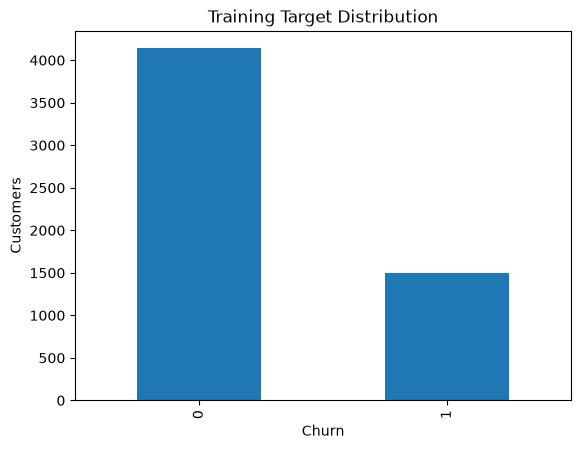

In [5]:
# Plot Training Target Distribution
y_train.value_counts(
    normalize=True
)

class_distribution.plot(
    kind="bar"
)

plt.title(
    "Training Target Distribution"
)

plt.xlabel("Churn")
plt.ylabel("Customers")

plt.show()

In [6]:
#Logistic Regression + Class Weight


logistic_balanced = (
    LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight="balanced",
    )
)


logistic_balanced.fit(
    X_train,
    y_train,
)


print(
    "Logistic Regression "
    "with class_weight trained successfully."
)

Logistic Regression with class_weight trained successfully.


In [7]:
# Evaluate Logistic Regression + Class Weight
y_pred_lr_balanced = (
    logistic_balanced.predict(
        X_test
    )
)


y_prob_lr_balanced = (
    logistic_balanced.predict_proba(
        X_test
    )[:, 1]
)


logistic_balanced_metrics = (
    evaluate_classifier(
        "Logistic Regression - Class Weight",
        y_test,
        y_pred_lr_balanced,
        y_prob_lr_balanced,
    )
)


pd.DataFrame(
    [
        logistic_balanced_metrics
    ]
).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression - Class Weight,0.7431,0.5105,0.7807,0.6173,0.8416,0.6334


In [8]:
#Random Forest + class_weight

rf_balanced = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)


rf_balanced.fit(
    X_train,
    y_train,
)


print(
    "Random Forest with "
    "class_weight trained successfully."
)

Random Forest with class_weight trained successfully.


In [9]:
# Evaluate Random Forest Balanced - Evaluate Random Forest + Class Weight
y_pred_rf_balanced = (
    rf_balanced.predict(
        X_test
    )
)

y_prob_rf_balanced = (
    rf_balanced.predict_proba(
        X_test
    )[:, 1]
)


rf_balanced_metrics = (
    evaluate_classifier(
        "Random Forest + class_weight",
        y_test,
        y_pred_rf_balanced,
        y_prob_rf_balanced,
    )
)


pd.DataFrame(
    [
        rf_balanced_metrics
    ]
).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest + class_weight,0.7594,0.5406,0.623,0.5789,0.8218,0.6083


In [10]:
# Compare Class Weight Models
class_weight_comparison = (
    pd.DataFrame(
        [
            logistic_balanced_metrics,
            rf_balanced_metrics,
        ]
    )
)


display(
    class_weight_comparison.round(4)
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression - Class Weight,0.7431,0.5105,0.7807,0.6173,0.8416,0.6334
1,Random Forest + class_weight,0.7594,0.5406,0.6230,0.5789,0.8218,0.6083


In [11]:
# SMOTE
from imblearn.over_sampling import SMOTE


smote = SMOTE(
    random_state=42
)


X_train_smote, y_train_smote = (
    smote.fit_resample(
        X_train,
        y_train,
    )
)


print(
    "Before SMOTE:"
)

print(
    y_train.value_counts()
)


print(
    "\nAfter SMOTE:"
)

print(
    y_train_smote.value_counts()
)

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


In [12]:
#Logistic Regression + SMOTE
logistic_smote = LogisticRegression(
    max_iter=1000,
    random_state=42,
)


logistic_smote.fit(
    X_train_smote,
    y_train_smote,
)


y_pred_lr_smote = (
    logistic_smote.predict(
        X_test
    )
)


y_prob_lr_smote = (
    logistic_smote.predict_proba(
        X_test
    )[:, 1]
)


lr_smote_metrics = (
    evaluate_classifier(
        "Logistic Regression + SMOTE",
        y_test,
        y_pred_lr_smote,
        y_prob_lr_smote,
    )
)


pd.DataFrame(
    [
        lr_smote_metrics
    ]
).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression + SMOTE,0.7388,0.5052,0.7861,0.6151,0.8407,0.6365


In [13]:
#Cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)
#Define scoring
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}
#Cross-validation Logistic
cv_results = cross_validate(
    logistic_balanced,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
)
#
cv_summary = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
        ],
        "Mean": [
            cv_results["test_accuracy"].mean(),
            cv_results["test_precision"].mean(),
            cv_results["test_recall"].mean(),
            cv_results["test_f1"].mean(),
            cv_results["test_roc_auc"].mean(),
        ],
        "Std": [
            cv_results["test_accuracy"].std(),
            cv_results["test_precision"].std(),
            cv_results["test_recall"].std(),
            cv_results["test_f1"].std(),
            cv_results["test_roc_auc"].std(),
        ],
    }
)

cv_summary

,Metric,Mean,Std
0,Accuracy,0.747428,0.013132
1,Precision,0.515515,0.016216
2,Recall,0.794649,0.037992
3,F1,0.625217,0.022330
4,ROC-AUC,0.845140,0.012485


In [14]:
#Hyperparameter Tuning - RandomizedSearchCV
rf_params = {
    "n_estimators": [
        100,
        200,
        300,
        500,
    ],

    "max_depth": [
        None,
        5,
        10,
        20,
    ],

    "min_samples_split": [
        2,
        5,
        10,
    ],

    "min_samples_leaf": [
        1,
        2,
        4,
    ],

    "max_features": [
        "sqrt",
        "log2",
    ],
}

#Search
rf_random_search = RandomizedSearchCV(

    estimator=RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
    param_distributions=rf_params,
    n_iter=30,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
#Train
rf_random_search.fit(
    X_train,
    y_train,
)

print(
    "Best parameters:"
)

print(
    rf_random_search.best_params_
)

print(
    "\nBest CV ROC-AUC:"
)

print(
    rf_random_search.best_score_
)

best_rf_model = (
    rf_random_search.best_estimator_
)
print(best_rf_model)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters:
{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 5}

Best CV ROC-AUC:
0.8452549550594505
RandomForestClassifier(class_weight='balanced', max_depth=5, n_estimators=500,
                       n_jobs=-1, random_state=42)


In [15]:
rf_grid_params = {

    "n_estimators": [
        250,
        300,
        350,
    ],

    "max_depth": [
        8,
        10,
        12,
    ],

    "min_samples_split": [
        4,
        5,
        6,
    ],

    "min_samples_leaf": [
        1,
        2,
        3,
    ],
}

rf_grid_search = GridSearchCV(

    estimator=RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),

    param_grid=rf_grid_params,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1,
)
rf_grid_search.fit(
    X_train,
    y_train,
)
print(
    "Best parameters:",
    rf_grid_search.best_params_
)

print(
    "Best CV ROC-AUC:",
    rf_grid_search.best_score_
)

print(
    "Best CV ROC-AUC:",
    rf_grid_search.best_estimator_
)


Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best parameters: {'max_depth': 8, 'min_samples_leaf': 2, 'min_samples_split': 6, 'n_estimators': 250}
Best CV ROC-AUC: 0.8471375097730294
Best CV ROC-AUC: RandomForestClassifier(class_weight='balanced', max_depth=8, min_samples_leaf=2,
                       min_samples_split=6, n_estimators=250, n_jobs=-1,
                       random_state=42)


In [16]:
# Evaluate Tuned Random Forest
# Default Threshold = 0.50
best_rf_model = (
    rf_grid_search.best_estimator_
)


y_pred_rf_tuned = (
    best_rf_model.predict(
        X_test
    )
)


y_prob_rf_tuned = (
    best_rf_model.predict_proba(
        X_test
    )[:, 1]
)
#Metrics
rf_tuned_metrics = (
    evaluate_classifier(
        "Random Forest - Tuned",
        y_test,
        y_pred_rf_tuned,
        y_prob_rf_tuned,
    )
)


pd.DataFrame(
    [
        rf_tuned_metrics
    ]
).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest - Tuned,0.7551,0.5261,0.7807,0.6286,0.8419,0.6524


In [17]:
# XGBoost
from xgboost import XGBClassifier


xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss",
)


xgb_model.fit(
    X_train,
    y_train,
)


y_pred_xgb = (
    xgb_model.predict(
        X_test
    )
)


y_prob_xgb = (
    xgb_model.predict_proba(
        X_test
    )[:, 1]
)


xgb_metrics = (
    evaluate_classifier(
        "XGBoost",
        y_test,
        y_pred_xgb,
        y_prob_xgb,
    )
)


pd.DataFrame(
    [
        xgb_metrics
    ]
).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost,0.7757,0.5906,0.5053,0.5447,0.8183,0.6031


In [18]:

# Threshold Optimization
# Model: Tuned Random Forest

threshold_results = []


thresholds = np.arange(
    0.20,
    0.81,
    0.02,
)


for threshold in thresholds:

    # Convert churn probability into
    # binary prediction using current threshold
    y_pred_threshold = (
        y_prob_rf_tuned
        >= threshold
    ).astype(int)


    precision = precision_score(
        y_test,
        y_pred_threshold,
        zero_division=0,
    )


    recall = recall_score(
        y_test,
        y_pred_threshold,
        zero_division=0,
    )


    f1 = f1_score(
        y_test,
        y_pred_threshold,
        zero_division=0,
    )


    threshold_results.append(
        {
            "Threshold":
                float(threshold),

            "Precision":
                float(precision),

            "Recall":
                float(recall),

            "F1":
                float(f1),
        }
    )


threshold_df = pd.DataFrame(
    threshold_results
)


display(
    threshold_df.round(4)
)

,Threshold,Precision,Recall,F1
0,0.20,0.3838,0.9626,0.5488
1,0.22,0.3921,0.9519,0.5554
2,0.24,0.4023,0.9412,0.5637
3,0.26,0.4176,0.9412,0.5785
4,0.28,0.4251,0.9251,0.5825
5,0.30,0.4320,0.9091,0.5857
6,0.32,0.4402,0.8957,0.5903
7,0.34,0.4479,0.8850,0.5948
8,0.36,0.4577,0.8824,0.6027
9,0.38,0.4652,0.8583,0.6034


In [19]:
# Select Best Decision Threshold
# Threshold Selection Metric: F1 Score
best_threshold_index = (
    threshold_df[
        "F1"
    ].idxmax()
)


best_threshold_row = (
    threshold_df.loc[
        best_threshold_index
    ]
)


best_threshold = float(
    best_threshold_row[
        "Threshold"
    ]
)


print(
    "Best threshold:",
    round(
        best_threshold,
        4,
    )
)


print(
    "\nMetrics at best threshold:"
)


display(
    best_threshold_row
    .to_frame()
    .T
    .round(4)
)

Best threshold: 0.48

Metrics at best threshold:


,Threshold,Precision,Recall,F1
14,0.48,0.5254,0.8021,0.6349


In [20]:
# Evaluate Tuned Random Forest
# with Optimized Threshold
y_pred_rf_optimized = (
    y_prob_rf_tuned
    >= best_threshold
).astype(int)


rf_optimized_metrics = (
    evaluate_classifier(
        "Random Forest - Tuned - Optimized Threshold",
        y_test,
        y_pred_rf_optimized,
        y_prob_rf_tuned,
    )
)


rf_optimized_metrics_df = (
    pd.DataFrame(
        [
            rf_optimized_metrics
        ]
    )
)


display(
    rf_optimized_metrics_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest - Tuned - Optimized Threshold,0.7551,0.5254,0.8021,0.6349,0.8419,0.6524


In [21]:
# Default vs Optimized Threshold Comparison
threshold_comparison = pd.DataFrame(
    [
        {
            **rf_tuned_metrics,
            "Threshold": 0.50,
        },

        {
            **rf_optimized_metrics,
            "Threshold": best_threshold,
        },
    ]
)


threshold_comparison = (
    threshold_comparison[
        [
            "Model",
            "Threshold",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "PR-AUC",
        ]
    ]
)


display(
    threshold_comparison.round(4)
)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest - Tuned,0.50,0.7551,0.5261,0.7807,0.6286,0.8419,0.6524
1,Random Forest - Tuned - Optimized Threshold,0.48,0.7551,0.5254,0.8021,0.6349,0.8419,0.6524


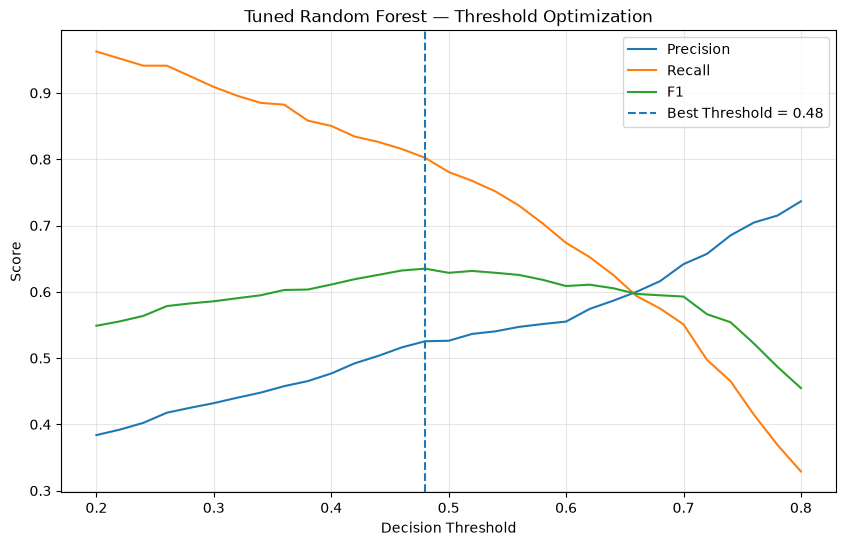

In [22]:
# Threshold Trade-off Visualization
plt.figure(
    figsize=(10, 6)
)


plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision",
)


plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall",
)


plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1",
)


plt.axvline(
    x=best_threshold,
    linestyle="--",
    label=(
        f"Best Threshold = "
        f"{best_threshold:.2f}"
    ),
)


plt.xlabel(
    "Decision Threshold"
)


plt.ylabel(
    "Score"
)


plt.title(
    "Tuned Random Forest — Threshold Optimization"
)


plt.legend()


plt.grid(
    alpha=0.3
)


plt.show()

In [23]:
#Final Model Comparison
optimization_results = pd.DataFrame(
    [
        logistic_balanced_metrics,
        rf_balanced_metrics,
        lr_smote_metrics,
        rf_tuned_metrics,
        rf_optimized_metrics,
        xgb_metrics,
    ]
)


final_results = pd.concat(
    [
        baseline_results,
        optimization_results,
    ],
    ignore_index=True,
)


final_results = (
    final_results
    .sort_values(
        by="ROC-AUC",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


display(
    final_results[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "PR-AUC",
        ]
    ].round(4)
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Gradient Boosting,0.8077,0.6873,0.5053,0.5824,0.8472,0.6614
1,Logistic Regression,0.7970,0.6467,0.5187,0.5757,0.8420,0.6358
2,Random Forest - Tuned - Optimized Threshold,0.7551,0.5254,0.8021,0.6349,0.8419,0.6524
3,Random Forest - Tuned,0.7551,0.5261,0.7807,0.6286,0.8419,0.6524
4,Logistic Regression - Class Weight,0.7431,0.5105,0.7807,0.6173,0.8416,0.6334
5,Logistic Regression + SMOTE,0.7388,0.5052,0.7861,0.6151,0.8407,0.6365
6,Decision Tree,0.7913,0.6093,0.5963,0.6027,0.8259,0.6167
7,Random Forest,0.7807,0.6073,0.4920,0.5436,0.8234,0.6118
8,Random Forest + class_weight,0.7594,0.5406,0.6230,0.5789,0.8218,0.6083
9,XGBoost,0.7757,0.5906,0.5053,0.5447,0.8183,0.6031


## Final Model Selection Strategy

The final model is not selected solely based on accuracy.

Because customer churn is an imbalanced classification problem,
model evaluation focuses on:

- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC

The tuned Random Forest is selected as the final classifier based
primarily on its ROC-AUC performance and overall balance across
classification metrics.

After selecting the classifier, the decision threshold is optimized
separately using F1-score.

This separates two decisions:

1. Model selection — based primarily on ROC-AUC.
2. Threshold selection — based on the highest F1-score.

Recall is particularly important in churn prediction because a false
negative represents a customer who is likely to churn but is not
identified by the model.

The optimized threshold therefore aims to improve the balance between
precision and recall while reducing the business cost of missed churn
customers.

In [24]:
# Save Final Model Comparison Metrics
METRICS_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "metrics"
)


METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


FINAL_METRICS_PATH = (
    METRICS_DIR
    / "final_model_metrics.csv"
)


final_results.to_csv(
    FINAL_METRICS_PATH,
    index=False,
)


print(
    "Final model comparison metrics saved:"
)

print(
    FINAL_METRICS_PATH
)

Final model comparison metrics saved:
d:\Research_Project\customer-churn-prediction\artifacts\metrics\final_model_metrics.csv


In [25]:
# Save Tuned Random Forest Training Artifact
import joblib


MODEL_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "models"
)


MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


TRAINING_MODEL_PATH = (
    MODEL_DIR
    / "churn_model.joblib"
)


joblib.dump(
    best_rf_model,
    TRAINING_MODEL_PATH,
)


print(
    "Tuned Random Forest training artifact saved:"
)

print(
    TRAINING_MODEL_PATH
)

Tuned Random Forest training artifact saved:
d:\Research_Project\customer-churn-prediction\artifacts\models\churn_model.joblib


In [26]:
# Export Selected Model Configuration
import json


SELECTED_MODEL_CONFIG_PATH = (
    MODEL_DIR
    / "selected_model_config.json"
)


selected_model_config = {

    "model_name":
        "Random Forest - Tuned",

    "classifier":
        type(
            best_rf_model
        ).__name__,

    "decision_threshold":
        float(
            best_threshold
        ),

    "model_selection_metric":
        "ROC-AUC",

    "threshold_selection_metric":
        "F1",

    "hyperparameters": {

        "n_estimators":
            int(
                best_rf_model
                .n_estimators
            ),

        "max_depth":
            (
                int(
                    best_rf_model
                    .max_depth
                )
                if
                best_rf_model
                .max_depth
                is not None
                else None
            ),

        "min_samples_split":
            int(
                best_rf_model
                .min_samples_split
            ),

        "min_samples_leaf":
            int(
                best_rf_model
                .min_samples_leaf
            ),

        "max_features":
            best_rf_model
            .max_features,

        "class_weight":
            best_rf_model
            .class_weight,

        "random_state":
            best_rf_model
            .random_state,
    },

    "metrics": {

        "accuracy":
            float(
                rf_optimized_metrics[
                    "Accuracy"
                ]
            ),

        "precision":
            float(
                rf_optimized_metrics[
                    "Precision"
                ]
            ),

        "recall":
            float(
                rf_optimized_metrics[
                    "Recall"
                ]
            ),

        "f1":
            float(
                rf_optimized_metrics[
                    "F1"
                ]
            ),

        "roc_auc":
            float(
                rf_optimized_metrics[
                    "ROC-AUC"
                ]
            ),

        "pr_auc":
            float(
                rf_optimized_metrics[
                    "PR-AUC"
                ]
            ),
    },
}


with open(
    SELECTED_MODEL_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        selected_model_config,
        file,
        indent=4,
    )


print(
    "Selected model configuration saved:"
)

print(
    SELECTED_MODEL_CONFIG_PATH
)

Selected model configuration saved:
d:\Research_Project\customer-churn-prediction\artifacts\models\selected_model_config.json


In [27]:
# Verify Phase 6 Artifacts
artifacts_to_check = {
    "Training model":
        TRAINING_MODEL_PATH,

    "Selected model config":
        SELECTED_MODEL_CONFIG_PATH,

    "Final comparison metrics":
        FINAL_METRICS_PATH,
}


for name, path in artifacts_to_check.items():

    status = (
        "OK"
        if path.exists()
        else "MISSING"
    )

    print(
        f"{status:8} | "
        f"{name:25} | "
        f"{path}"
    )

OK       | Training model            | d:\Research_Project\customer-churn-prediction\artifacts\models\churn_model.joblib
OK       | Selected model config     | d:\Research_Project\customer-churn-prediction\artifacts\models\selected_model_config.json
OK       | Final comparison metrics  | d:\Research_Project\customer-churn-prediction\artifacts\metrics\final_model_metrics.csv


In [28]:
# Verify Selected Model
print(
    "Final classifier:"
)

print(
    type(
        best_rf_model
    ).__name__
)


print(
    "\nBest threshold:"
)

print(
    round(
        best_threshold,
        4,
    )
)


print(
    "\nOptimized metrics:"
)

display(
    pd.DataFrame(
        [
            rf_optimized_metrics
        ]
    ).round(4)
)


print(
    "\nSelected model config:"
)

print(
    json.dumps(
        selected_model_config,
        indent=4,
    )
)

Final classifier:
RandomForestClassifier

Best threshold:
0.48

Optimized metrics:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest - Tuned - Optimized Threshold,0.7551,0.5254,0.8021,0.6349,0.8419,0.6524



Selected model config:
{
    "model_name": "Random Forest - Tuned",
    "classifier": "RandomForestClassifier",
    "decision_threshold": 0.47999999999999987,
    "model_selection_metric": "ROC-AUC",
    "threshold_selection_metric": "F1",
    "hyperparameters": {
        "n_estimators": 250,
        "max_depth": 8,
        "min_samples_split": 6,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "class_weight": "balanced",
        "random_state": 42
    },
    "metrics": {
        "accuracy": 0.7551454932576295,
        "precision": 0.5253940455341506,
        "recall": 0.8021390374331551,
        "f1": 0.6349206349206349,
        "roc_auc": 0.8419230669870056,
        "pr_auc": 0.6523944849375903
    }
}
